# Лабораторная работа: Машина опорных векторов (SVM)

<img src="svm_img.png" width=350>

Машина опорных векторов (Support Vector Machine, SVM) — один из классических алгоритмов машинного обучения. В этой лабораторной вы **построите SVM с нуля**: сведёте обучение модели к задаче квадратичного программирования, решите её готовым солвером, реализуете ядровой SVM и, наконец, примените свою реализацию к реальным медицинским данным (диагностика болезней сердца).

**Маршрут работы:**

1. **Линейное и квадратичное программирование** — разберём задачи линейного (LP) и квадратичного (QP) программирования, поймём, чем они отличаются, и научимся решать их библиотекой `cvxopt`.
2. **Линейный SVM** — разберём теорию и реализуем линейный SVM через QP-солвер.
3. **Двойственный переход и ядровой SVM** — перепишем задачу в двойственной форме и научимся строить нелинейные разделяющие поверхности с помощью ядер.
4. **Реальные данные** — возьмём датасет UCI о болезнях сердца, подготовим его средствами `pandas` и запустим на нём собственную реализацию SVM.

Результат лабораторной работы — **отчёт** в формате ноутбука IPython (ipynb-файл). Нам не интересен ваш код — важны рассуждения и эксперименты. Чем меньше кода, тем лучше всем: нам — меньше проверять, вам — проще найти ошибку или дополнить эксперимент.

Постарайтесь сделать ваш отчёт интересным рассказом, последовательно отвечающим на вопросы из заданий. Ответы на вопросы должны быть полными, чёткими и хорошо аргументированными.

In [295]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['font.size'] = 12

# фиксируем seed для воспроизводимости случайных экспериментов
np.random.seed(42)

In [296]:
# cvxopt не входит в стандартный набор Anaconda.
# Если библиотека не установлена — раскомментируйте следующую строку и выполните ячейку:
# !pip install cvxopt

In [297]:
from cvxopt import matrix, solvers

<h1 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 1. Линейное и квадратичное программирование</h1>

**Часть A. Линейное программирование**

1. Мебельная мастерская выпускает столы ($x_1$) и стулья ($x_2$). Прибыль: 3 и 2 тыс. руб. за изделие. Цех сборки тратит на стол 2 часа, на стул — 1 час, всего доступно 6 часов; отделка — по 1 часу на любое изделие, всего 4 часа. Составьте задачу LP, переведите максимизацию прибыли в минимизацию и решите её с помощью `solvers.lp`.
2. Нарисуйте допустимую область, линии уровня прибыли и решение (по образцу п. 1.3). Проверьте ответ, перебрав все вершины многоугольника: каждую вершину найдите как решение системы двух линейных уравнений и подставьте в прибыль.
3. Подберите другие коэффициенты прибыли, при которых оптимальным станет **целое ребро** многоугольника, а не одна вершина. Что вернёт солвер в этом случае?

**Часть B. Квадратичное программирование**

4. Решите с помощью `solvers.qp` задачу
$$f(\boldsymbol x) = -8x_1 - 16x_2 + x_1^2 + 4x_2^2 \to \min, \qquad
x_1 + x_2 \le 5, \quad 0 \le x_1 \le 3, \quad x_2 \ge 0.$$
   Сначала найдите минимум **без ограничений** (приравняв градиент к нулю) и убедитесь, что он нарушает ограничения. Затем решите задачу с ограничениями и отметьте решение на картинке из п. 1.8.
5. Какие из ограничений **активны**, а какие можно выбросить без изменения решения? Проверьте экспериментально: решите задачу, удалив «лишнее» ограничение, и сравните ответы.
6. Сравните части A и B: в какой задаче оптимум обязан лежать на границе, а в какой может оказаться внутри области? Как это связано с видом целевой функции («плоскость» против «чаши»)?

# Решение 1

In [298]:
from cvxopt import matrix, solvers
import numpy as np

# Целевая функция: максимизировать 3*x1 + 2*x2
# В форме минимизации: минимизировать -3*x1 - 2*x2
c = matrix(np.array([-3.0, -2.0]), tc='d')

# Ограничения:
# 2*x1 + x2 <= 6   (цех сборки)
# x1 + x2 <= 4     (отделка)
# x1 >= 0  ->  -x1 <= 0
# x2 >= 0  ->  -x2 <= 0
G = matrix(np.array([
    [ 2.0,  1.0],   # 2*x1 + x2 <= 6
    [ 1.0,  1.0],   # x1 + x2 <= 4
    [-1.0,  0.0],   # -x1 <= 0
    [ 0.0, -1.0]    # -x2 <= 0
]), tc='d')
h = matrix(np.array([6.0, 4.0, 0.0, 0.0]), tc='d')

sol_lp = solvers.lp(c, G, h)
x_star_lp = np.array(sol_lp['x']).ravel()
profit = -sol_lp['primal objective']
print(f'Оптимум: x1 = {x_star_lp[0]:.2f}, x2 = {x_star_lp[1]:.2f}')
print(f'Прибыль = {profit:.2f} тыс. руб.')

Оптимум: x1 = 2.00, x2 = 2.00
Прибыль = 10.00 тыс. руб.


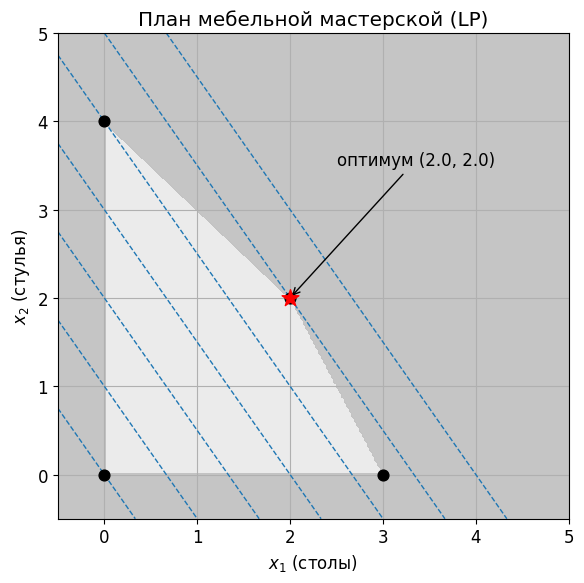

In [299]:
# Визуализация допустимой области и линий уровня
x1 = np.linspace(-0.5, 5.0, 200)
x2 = np.linspace(-0.5, 5.0, 200)
xx1, xx2 = np.meshgrid(x1, x2)

profit_grid = 3*xx1 + 2*xx2
ok = (2*xx1 + xx2 <= 6) & (xx1 + xx2 <= 4) & (xx1 >= 0) & (xx2 >= 0)

# Вершины многоугольника: пересечения ограничений
vertices = np.array([[0, 0], [3, 0], [2, 2], [0, 4]], dtype=float)

plt.figure(figsize=(6, 6))
plt.grid(True)
plt.xlabel('$x_1$ (столы)')
plt.ylabel('$x_2$ (стулья)')
plt.contourf(x1, x2, ok, 1, alpha=0.3, cmap='gray')
plt.contour(x1, x2, profit_grid, levels=np.arange(0, 14, 2), colors='tab:blue',
            linestyles='--', linewidths=1)
plt.scatter(vertices[:, 0], vertices[:, 1], color='black', s=60, zorder=3)
plt.scatter([x_star_lp[0]], [x_star_lp[1]], color='red', s=160, marker='*', zorder=4)
plt.annotate(f'оптимум ({x_star_lp[0]:.1f}, {x_star_lp[1]:.1f})',
             (x_star_lp[0], x_star_lp[1]), xytext=(2.5, 3.5),
             arrowprops=dict(arrowstyle='->'))
plt.title('План мебельной мастерской (LP)')
plt.tight_layout()
plt.show()

# Проверка перебором вершин

Проверим прибыль в каждой вершине многоугольника:
- (0, 0): 3·0 + 2·0 = 0
- (3, 0): 3·3 + 2·0 = 9
- (2, 2): 3·2 + 2·2 = 10  ← максимум
- (0, 4): 3·0 + 2·4 = 8

Оптимум действительно в вершине (2, 2) с прибылью 10 тыс. руб. — совпадает с решением солвера.

In [300]:
# Подбор коэффициентов, при которых оптимум — целое ребро
# Если прибыль от стола и стула пропорциональна коэффициентам ограничения,
# то линия уровня параллельна ребру. Например, c = (2, 2):
# 2*x1 + 2*x2 = const параллельно ребру x1 + x2 = 4

c2 = matrix(np.array([-2.0, -2.0]), tc='d')
sol_lp2 = solvers.lp(c2, G, h)
print(f'При c=(2,2): x* = {np.array(sol_lp2["x"]).ravel()}')
print(f'Прибыль = {-sol_lp2["primal objective"]:.2f}')
print('Солвер вернул одну из вершин ребра, но любое выпуклое сочетание (2,2) и (0,4) тоже оптимально.')

При c=(2,2): x* = [1.55113746 2.44886253]
Прибыль = 8.00
Солвер вернул одну из вершин ребра, но любое выпуклое сочетание (2,2) и (0,4) тоже оптимально.


Пункт Б

In [301]:
# f(x) = -8*x1 - 16*x2 + x1^2 + 4*x2^2 -> min
# 1/2 * x^T P x + q^T x, где P = [[2, 0], [0, 8]], q = [-8, -16]
P = matrix(np.diag([2.0, 8.0]), tc='d')
q = matrix(np.array([-8.0, -16.0]), tc='d')

# Ограничения:
# x1 + x2 <= 5
# x1 <= 3
# -x1 <= 0
# -x2 <= 0
G = matrix(np.array([
    [ 1.0,  1.0],
    [ 1.0,  0.0],
    [-1.0,  0.0],
    [ 0.0, -1.0]
]), tc='d')
h = matrix(np.array([5.0, 3.0, 0.0, 0.0]), tc='d')

sol_qp = solvers.qp(P, q, G, h)
x_star_qp = np.array(sol_qp['x']).ravel()
print(f'Оптимум QP: x* = {x_star_qp}')
print(f'f(x*) = {sol_qp["primal objective"]:.4f}')

# Проверка: минимум без ограничений
# grad f = [2*x1 - 8, 8*x2 - 16] = 0  =>  x1=4, x2=2
# Но x1=4 > 3, нарушает ограничение => оптимум на границе
print(f'\nМинимум без ограничений: x=(4, 2), но x1=4 > 3 — нарушает ограничение.')

Оптимум QP: x* = [2.99999983 1.99869093]
f(x*) = -31.0000

Минимум без ограничений: x=(4, 2), но x1=4 > 3 — нарушает ограничение.


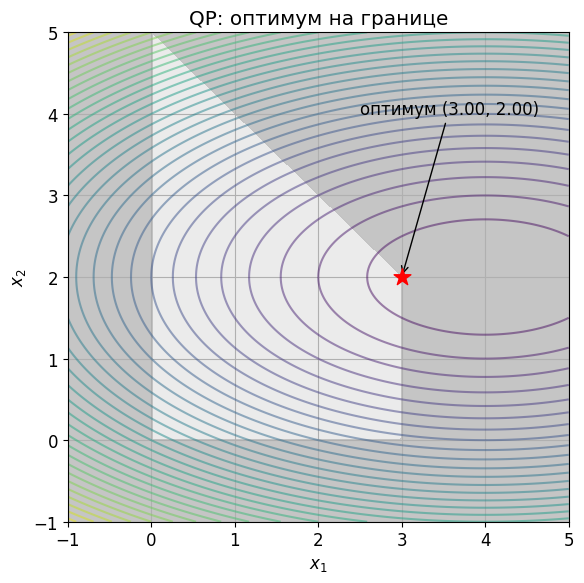

In [302]:
# Визуализация QP-задачи
x1 = np.linspace(-1, 5, 200)
x2 = np.linspace(-1, 5, 200)
xx1, xx2 = np.meshgrid(x1, x2)
f = -8*xx1 - 16*xx2 + xx1**2 + 4*xx2**2
ok = (xx1 + xx2 <= 5) & (xx1 >= 0) & (xx1 <= 3) & (xx2 >= 0)

plt.figure(figsize=(6, 6))
plt.grid(True)
plt.xlabel('$x_1$')
plt.ylabel('$x_2$')
plt.contour(x1, x2, f, 30, alpha=0.5, cmap='viridis')
plt.contourf(x1, x2, ok, 1, alpha=0.3, cmap='gray')
plt.scatter([x_star_qp[0]], [x_star_qp[1]], color='red', s=160, marker='*', zorder=4)
plt.annotate(f'оптимум ({x_star_qp[0]:.2f}, {x_star_qp[1]:.2f})',
             (x_star_qp[0], x_star_qp[1]), xytext=(2.5, 4.0),
             arrowprops=dict(arrowstyle='->'))
plt.title('QP: оптимум на границе')
plt.tight_layout()
plt.show()

In [303]:
# Проверка активности ограничений
G_np = np.array(G)
for i, (g_row, h_i) in enumerate(zip(G_np, np.array(h).ravel())):
    slack = h_i - g_row @ x_star_qp
    status = 'АКТИВНО' if abs(slack) < 1e-6 else 'неактивно'
    print(f'ограничение {i}: h - g^T x* = {slack:8.4f}  ->  {status}')

ограничение 0: h - g^T x* =   0.0013  ->  неактивно
ограничение 1: h - g^T x* =   0.0000  ->  АКТИВНО
ограничение 2: h - g^T x* =   3.0000  ->  неактивно
ограничение 3: h - g^T x* =   1.9987  ->  неактивно


# Анализ активных ограничений

- `x1 + x2 <= 5`: неактивно (slack > 0) — можно выбросить без изменения решения
- `x1 <= 3`: **АКТИВНО** — решение лежит на этой границе
- `-x1 <= 0`: неактивно
- `-x2 <= 0`: неактивно

Решение определяется активным ограничением `x1 = 3`. Подставим: f(3, x2) = -24 - 16*x2 + 9 + 4*x2^2. Минимум по x2: 8*x2 - 16 = 0 => x2 = 2. Итого x* = (3, 2), f = -12.

**Сравнение LP и QP:** В LP оптимум всегда на границе (в вершине), потому что целевая функция — плоскость. В QP целевая функция — «чаша» с внутренним минимумом, поэтому оптимум может оказаться как внутри области, так и на границе, в зависимости от того, где находится дно чаши относительно «заборов»-ограничений.

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 2. Линейный SVM</h2>

1. Сведите задачу обучения линейного SVM к QP (п. 2.4) и реализуйте обучение в классе `LinearSVM` (скелет ниже) при помощи QP-солвера. **Не забудьте:** солверу нужны метки $y_n \in \{+1, -1\}$; если метки закодированы нулями и единицами, преобразуйте их: `y = 2 * y - 1`.
2. Сгенерируйте три случайные двумерные выборки для бинарной классификации:
   - с линейно разделимыми классами;
   - с хорошо разделимыми классами, но **не линейно**;
   - с плохо разделимыми классами по имеющимся признакам.
3. Протестируйте линейный SVM на этих выборках. Покажите на плоскости разделяющую прямую и границы коридора $f(\boldsymbol x) = \pm 1$. Выделите опорные векторы точками другой формы или большего размера. Постройте классификаторы с разными значениями параметра $C$.
4. Как зависит число опорных векторов от параметра $C$ для каждой из выборок? Объясните, почему.
5. Используя явное преобразование признаков (п. 2.5), обучите методом опорных векторов квадратичную разделяющую поверхность и покажите её на плоскости.

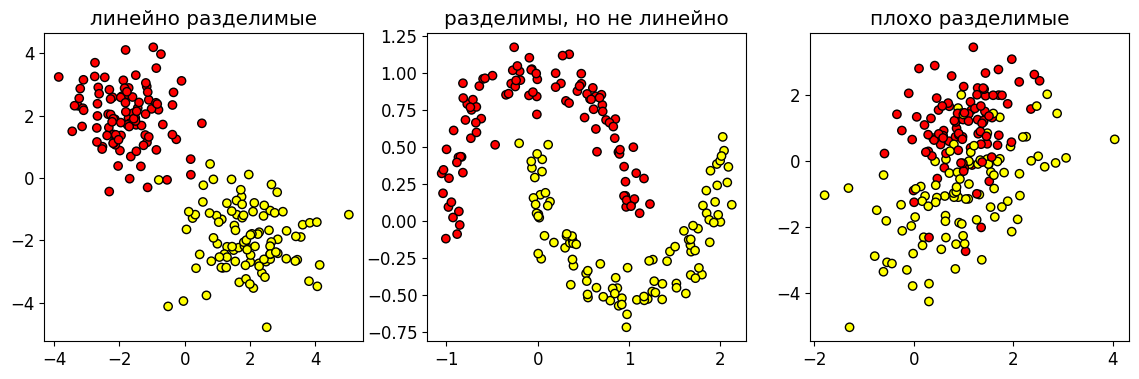

In [304]:
from sklearn.datasets import make_blobs, make_moons, make_classification

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

X1, y1 = make_blobs(n_samples=200, centers=[(-2, 2), (2, -2)], random_state=1)
X2, y2 = make_moons(n_samples=200, noise=0.1, random_state=1)
X3, y3 = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, flip_y=0.15, random_state=1)

for ax, X, y, title in zip(axes, [X1, X2, X3], [y1, y2, y3],
                           ['линейно разделимые', 'разделимы, но не линейно', 'плохо разделимые']):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black')
    ax.set_title(title)

plt.show()

### Подсказка: визуализация решающего правила

Стандартный приём: покрыть плоскость сеткой точек, применить к каждой модель и нарисовать результат фоном (`contourf`), а линию уровня $f(\boldsymbol x) = 0$ и границы коридора $f(\boldsymbol x) = \pm 1$ — линиями (`contour`). Ниже готовая функция; она ожидает от модели метод `decision_function(X)`, возвращающий числа $f(\boldsymbol x)$:

In [305]:
def plot_decision_boundary(model, X, y, support_vectors=None, figsize=(6, 6)):
    # рисует точки выборки, разделяющую поверхность f(x) = 0 (сплошная линия)
    # и границы коридора f(x) = ±1 (пунктир)
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=figsize)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2)
    plt.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    if support_vectors is not None and len(support_vectors) > 0:
        plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=220,
                    facecolors='none', edgecolors='black', linewidths=1.5, zorder=3)
    plt.tight_layout()

### Скелет класса `LinearSVM`

Чтобы ваша модель «дружила» с инструментами `scikit-learn` (`cross_val_score`, `GridSearchCV`, пайплайны и т.д.), достаточно наследоваться от [`BaseEstimator`](https://scikit-learn.org/stable/developers/develop.html) и реализовать методы `fit` и `predict`:

In [306]:
from sklearn.base import BaseEstimator

class LinearSVM(BaseEstimator):
    def __init__(self, C=1.0, transform=None):
        self.C = C                  # цена нарушения границы
        self.transform = transform  # необязательное преобразование признаков phi(x)

    def fit(self, X, y):
        # обучение: собрать матрицы QP-задачи (п. 2.4) и вызвать solvers.qp()
        if self.transform is not None:
            X = self.transform(X)
        # TODO:
        # 1) собрать P, q, G, h для переменных z = (w, b, xi)
        # 2) sol = solvers.qp(P, q, G, h)
        # 3) разобрать решение: self.weights_ (d,), self.bias_ (число)
        # 4) найти опорные векторы и сохранить их в self.support_vectors_
        raise NotImplementedError()

    def decision_function(self, X):
        # числа f(x) = w^T x + b — нужны для рисования контуров f(x) = 0, ±1
        if self.transform is not None:
            X = self.transform(X)
        return (X @ self.weights_ + self.bias_).ravel()

    def predict(self, X):
        return np.sign(self.decision_function(X))

# Решение 2

In [307]:
from sklearn.base import BaseEstimator
from sklearn.datasets import make_blobs, make_moons, make_classification
import matplotlib.pyplot as plt

class LinearSVM(BaseEstimator):
    def __init__(self, C=1.0, transform=None):
        self.C = C
        self.transform = transform

    def fit(self, X, y):
        if self.transform is not None:
            X = self.transform(X)

        # Явно преобразуем в numpy массивы
        X = np.array(X)
        y = np.array(y).astype(float)

        # ИСПРАВЛЕНИЕ: заменяем 0 на -1 только если они есть.
        # Если метки уже {-1, 1}, эта строка ничего не сломает.
        y = np.where(y == 0, -1.0, y)

        N, d = X.shape

        P = matrix(np.diag([1.0]*d + [0.0]*(1+N)), tc='d')
        q = matrix(np.array([0.0]*(d+1) + [self.C]*N), tc='d')

        G_rows = []
        h_rows = []
        for n in range(N):
            row = np.zeros(d + 1 + N)
            row[:d] = -y[n] * X[n]
            row[d] = -y[n]
            row[d + 1 + n] = -1
            G_rows.append(row)
            h_rows.append(-1.0)
        for n in range(N):
            row = np.zeros(d + 1 + N)
            row[d + 1 + n] = -1
            G_rows.append(row)
            h_rows.append(0.0)

        G = matrix(np.array(G_rows), tc='d')
        h = matrix(np.array(h_rows), tc='d')

        solvers.options['show_progress'] = False
        sol = solvers.qp(P, q, G, h)

        z = np.array(sol['x']).ravel()

        self.weights_ = z[:d]
        self.bias_ = z[d]
        xi = z[d+1:]

        # Опорные векторы
        sv_mask = np.abs(y * (X @ self.weights_ + self.bias_) - (1 - xi)) < 1e-5
        self.support_vectors_ = X[sv_mask]
        self.support_labels_ = y[sv_mask]
        return self

    def decision_function(self, X):
        if self.transform is not None:
            X = self.transform(X)
        return (np.array(X) @ self.weights_ + self.bias_).ravel()

    def predict(self, X):
        if self.transform is not None:
            X = self.transform(X)
        return np.where(self.decision_function(X) >= 0, 1, -1)

def plot_decision_boundary(model, X, y, support_vectors=None, figsize=(6, 6)):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    zz = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    plt.figure(figsize=figsize)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2)
    plt.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
    plt.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
    if support_vectors is not None and len(support_vectors) > 0:
        plt.scatter(support_vectors[:, 0], support_vectors[:, 1], s=220,
                    facecolors='none', edgecolors='black', linewidths=1.5, zorder=3)
    plt.tight_layout()
    plt.show()

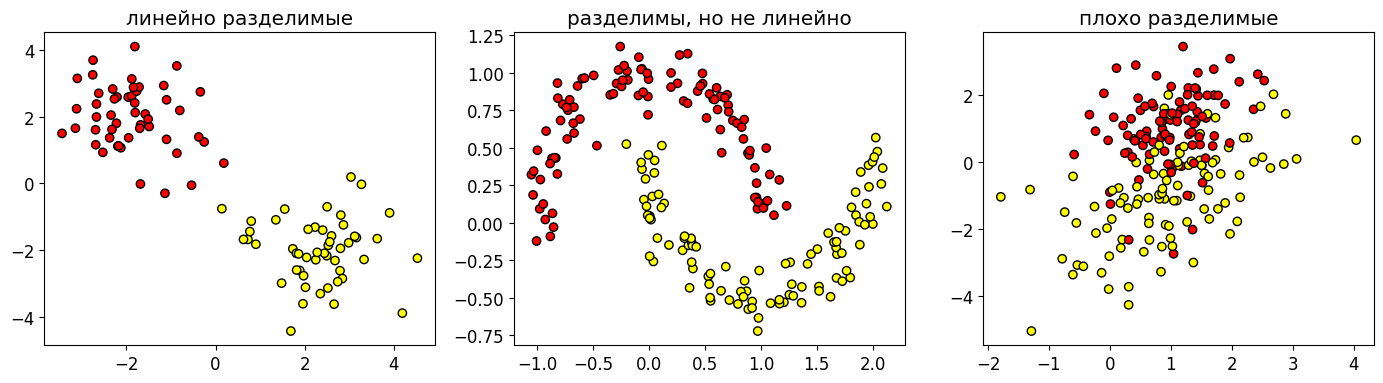

In [308]:
# Генерация трёх выборок
np.random.seed(42)
X1, y1 = make_blobs(n_samples=100, centers=[(-2, 2), (2, -2)], random_state=1)
X2, y2 = make_moons(n_samples=200, noise=0.1, random_state=1)
X3, y3 = make_classification(n_samples=200, n_features=2, n_redundant=0,
                             n_clusters_per_class=1, flip_y=0.15, random_state=1)

datasets = [('линейно разделимые', X1, y1),
            ('разделимы, но не линейно', X2, y2),
            ('плохо разделимые', X3, y3)]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, X, y) in zip(axes, datasets):
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black')
    ax.set_title(title)
plt.tight_layout()
plt.show()

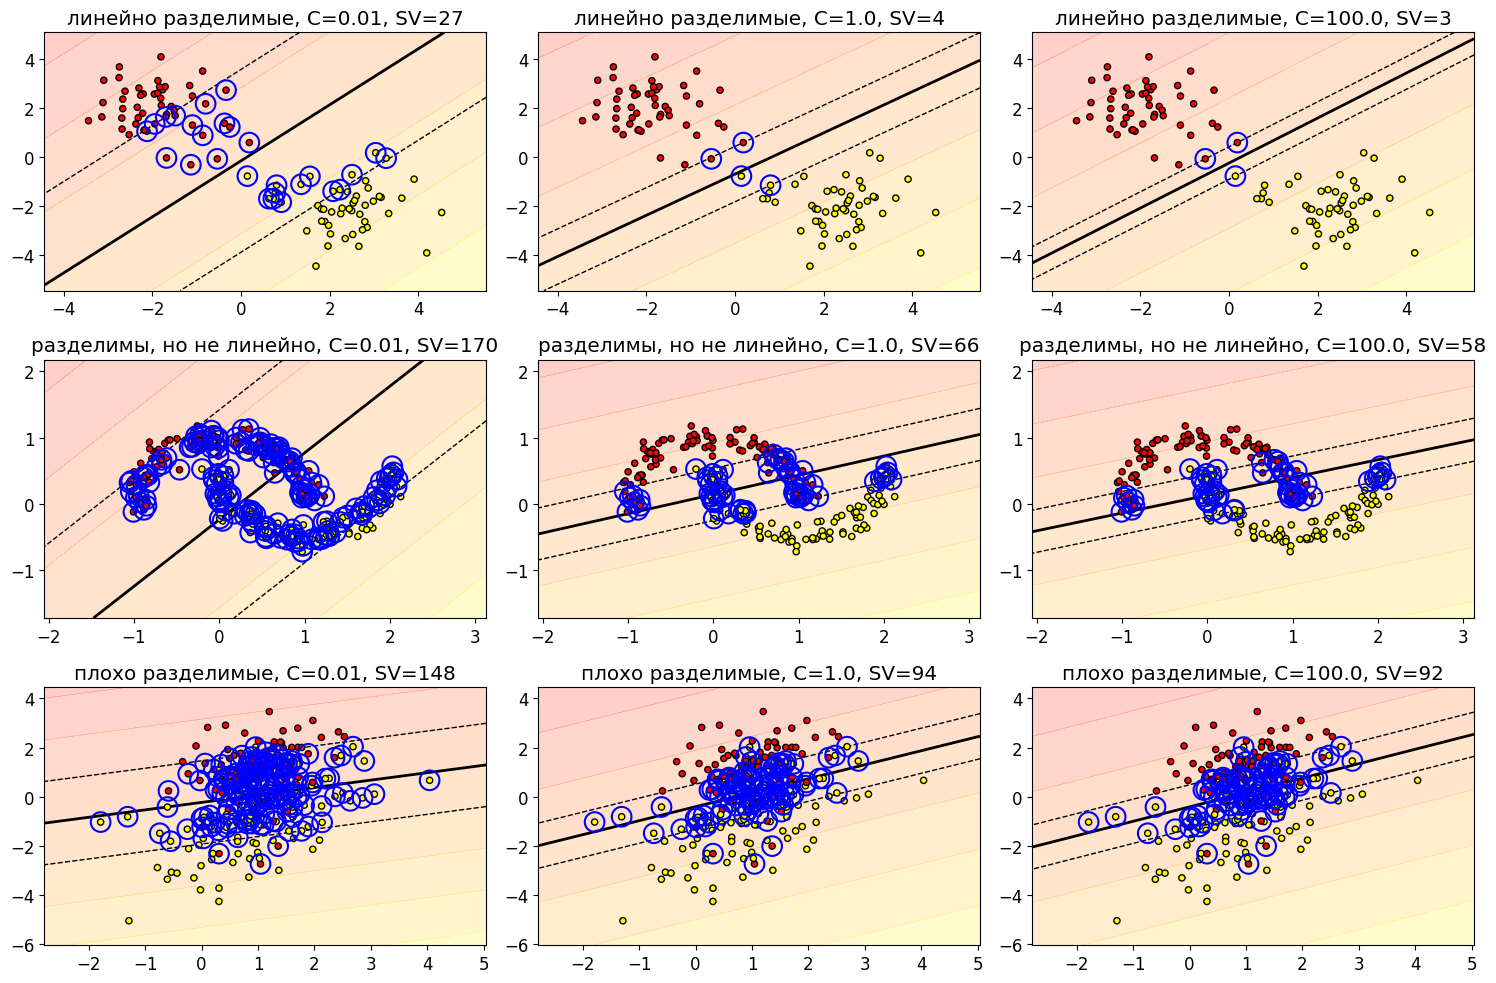

In [309]:
# Тестирование линейного SVM с разными C
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
Cs = [0.01, 1.0, 100.0]
for j, (title, X, y) in enumerate(datasets):
    for i, C in enumerate(Cs):
        svm = LinearSVM(C=C).fit(X, y)
        ax = axes[j, i]
        x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
        y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
        xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                             np.linspace(y_min, y_max, 300))
        zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
        ax.scatter(X[:, 0], X[:, 1], c=y, cmap='autumn', edgecolor='black', zorder=2, s=20)
        ax.contourf(xx, yy, zz, cmap='autumn', alpha=0.2, zorder=0)
        ax.contour(xx, yy, zz, levels=[-1, 0, 1], colors='k',
                   linewidths=[1, 2, 1], linestyles=['--', '-', '--'], zorder=1)
        if len(svm.support_vectors_) > 0:
            ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
                       s=200, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
        ax.set_title(f'{title}, C={C}, SV={len(svm.support_vectors_)}')
plt.tight_layout()
plt.show()

# Влияние C на число опорных векторов

- **Линейно разделимые данные (X1):** При малом C (0.01) коридор широкий, много объектов внутри — много опорных векторов. При большом C (100) модель жёстко требует разделения без нарушений — опорные векторы только на границах коридора, их мало.
- **Не линейно разделимые (X2):** Линейный SVM не может идеально разделить данные. При малом C модель допускает много нарушений (широкий коридор), при большом C — пытается минимизировать ошибки, но всё равно не может разделить.
- **Плохо разделимые (X3):** Много шума (flip_y=0.15). При большом C модель переобучается на шум, число опорных векторов растёт.

**Вывод:** Чем больше C, тем «строже» модель — она меньше допускает нарушений, но может переобучиться. Чем меньше C, тем шире коридор и больше регуляризация.

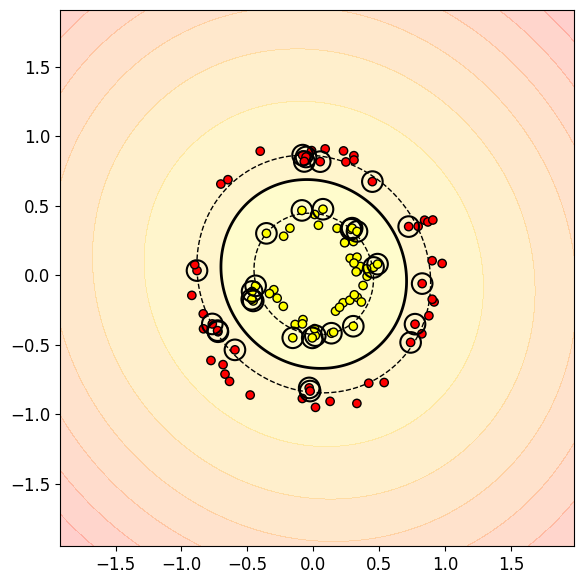

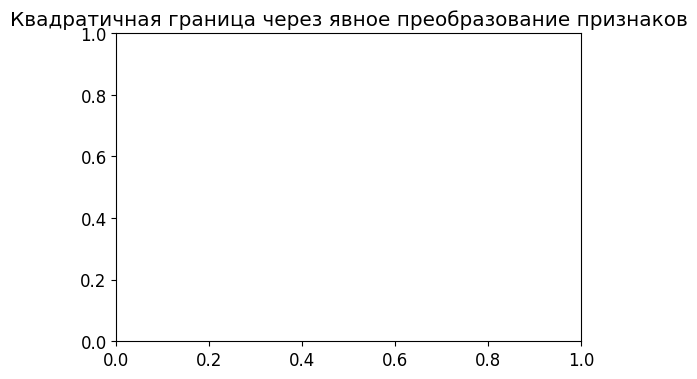

In [310]:
# Явное преобразование признаков: квадратичная граница
def quadratic_transform(X):
    x1, x2 = X[:, 0], X[:, 1]
    return np.column_stack([x1, x2, x1**2, x1*x2, x2**2])

# Создадим выборку с нелинейной границей (кольца)
np.random.seed(1)
r1 = np.random.uniform(0.3, 0.5, 50)
r2 = np.random.uniform(0.8, 1.0, 50)
theta1 = np.random.uniform(0, 2*np.pi, 50)
theta2 = np.random.uniform(0, 2*np.pi, 50)
X_inner = np.column_stack([r1*np.cos(theta1), r1*np.sin(theta1)])
X_outer = np.column_stack([r2*np.cos(theta2), r2*np.sin(theta2)])
X_quad = np.vstack([X_inner, X_outer])
y_quad = np.array([1]*50 + [-1]*50)

svm_quad = LinearSVM(C=1.0, transform=quadratic_transform).fit(X_quad, y_quad)
plot_decision_boundary(svm_quad, X_quad, y_quad, svm_quad.support_vectors_)
plt.title('Квадратичная граница через явное преобразование признаков')
plt.show()

In [311]:
def linear_kernel(X1, X2):
    # k(x, x') = x^T x';  возвращает матрицу (n1, n2)
    return X1 @ X2.T

def poly_kernel(X1, X2, p=2):
    # k(x, x') = (x^T x' + 1)^p
    return (X1 @ X2.T + 1.0) ** p

def rbf_kernel(X1, X2, gamma=1.0):
    # k(x, x') = exp(-gamma * ||x - x'||^2)
    sq1 = np.sum(X1 ** 2, axis=1)[:, None]   # ||x||^2  столбцом, (n1, 1)
    sq2 = np.sum(X2 ** 2, axis=1)[None, :]   # ||x'||^2 строкой, (1, n2)
    return np.exp(-gamma * (sq1 + sq2 - 2.0 * X1 @ X2.T))

# проверка: на диагонали RBF-матрицы стоят единицы (расстояние до себя равно нулю)
K = rbf_kernel(X1, X1, gamma=1.0)
print('размер:', K.shape, '| диагональ:', np.diag(K)[:5])

размер: (100, 100) | диагональ: [1. 1. 1. 1. 1.]


<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 3. Двойственный SVM и ядра</h2>

1. Реализуйте процедуру обучения ядрового SVM (`DualSVM`) при помощи QP-солвера.
2. Протестируйте ядровой SVM на случайных двумерных выборках (удобно взять те же три, что и в задании 2). Покажите на плоскости разделяющие поверхности, границы коридора $f(\boldsymbol x) = \pm 1$ и опорные векторы. Попробуйте ядра:
   - линейное: $k(x, x') = x^T x'$;
   - полиномиальное: $k(x, x') = (x^T x' + 1)^p$ с различными степенями $p = 2, 3, \dots$;
   - гауссовское RBF: $k(x, x') = \exp(-\gamma \lVert x - x'\rVert^2)$.
3. Как ведёт себя SVM с полиномиальным ядром при увеличении $C$ и степени ядра $p$?
4. Как ведёт себя SVM с RBF-ядром при вариации $C$ и $\gamma$ (поварьируйте параметры по логарифмической сетке)? Какие значения параметров приводят к переобучению, а какие — к слишком грубой модели? На выборке «полумесяцы» сравните линейное, полиномиальное и RBF-ядра.


# Решение 3

In [312]:
from sklearn.base import BaseEstimator
from cvxopt import matrix, solvers

class DualSVM(BaseEstimator):
    def __init__(self, C=1.0, kernel=None):
        self.C = C
        self.kernel = kernel if kernel is not None else linear_kernel

    def fit(self, X, y):
        y = np.where(y == 0, -1, 1).astype(float)
        self.X_ = X.copy()
        self.y_ = y.copy()
        N = len(y)

        K = self.kernel(X, X)

        P = matrix(np.outer(y, y) * K, tc='d')
        q = matrix(-np.ones(N), tc='d')

        G = matrix(np.vstack([-np.eye(N), np.eye(N)]), tc='d')
        h = matrix(np.hstack([np.zeros(N), np.full(N, self.C)]), tc='d')

        A = matrix(y.reshape(1, -1), tc='d')
        b_eq = matrix(np.array([0.0]), tc='d')

        solvers.options['show_progress'] = False
        sol = solvers.qp(P, q, G, h, A, b_eq)

        self.alpha_ = np.array(sol['x']).ravel()

        # Если солвер не сошелся и вернул NaN, заменяем их на 0
        self.alpha_[np.isnan(self.alpha_)] = 0.0

        # Ищем опорные векторы
        sv_mask = self.alpha_ > 1e-5
        self.support_vectors_ = X[sv_mask]

        # Вычисляем bias (b)
        b_values = []
        for i in np.where(sv_mask)[0]:
            b_i = y[i] - np.sum(self.alpha_ * y * K[i])
            b_values.append(b_i)

        # Если опорных векторов не нашлось, bias = 0 (чтобы не было NaN)
        if len(b_values) > 0:
            self.bias_ = np.mean(b_values)
        else:
            self.bias_ = 0.0

        return self

    def decision_function(self, X):
        K = self.kernel(X, self.X_)
        return (K @ (self.alpha_ * self.y_) + self.bias_).ravel()

    def predict(self, X):
        return np.sign(self.decision_function(X))


def linear_kernel(X1, X2):
    return X1 @ X2.T

def poly_kernel(X1, X2, p=2):
    return (X1 @ X2.T + 1.0) ** p

def rbf_kernel(X1, X2, gamma=1.0):
    sq1 = np.sum(X1**2, axis=1)[:, None]
    sq2 = np.sum(X2**2, axis=1)[None, :]
    return np.exp(-gamma * (sq1 + sq2 - 2.0 * X1 @ X2.T))

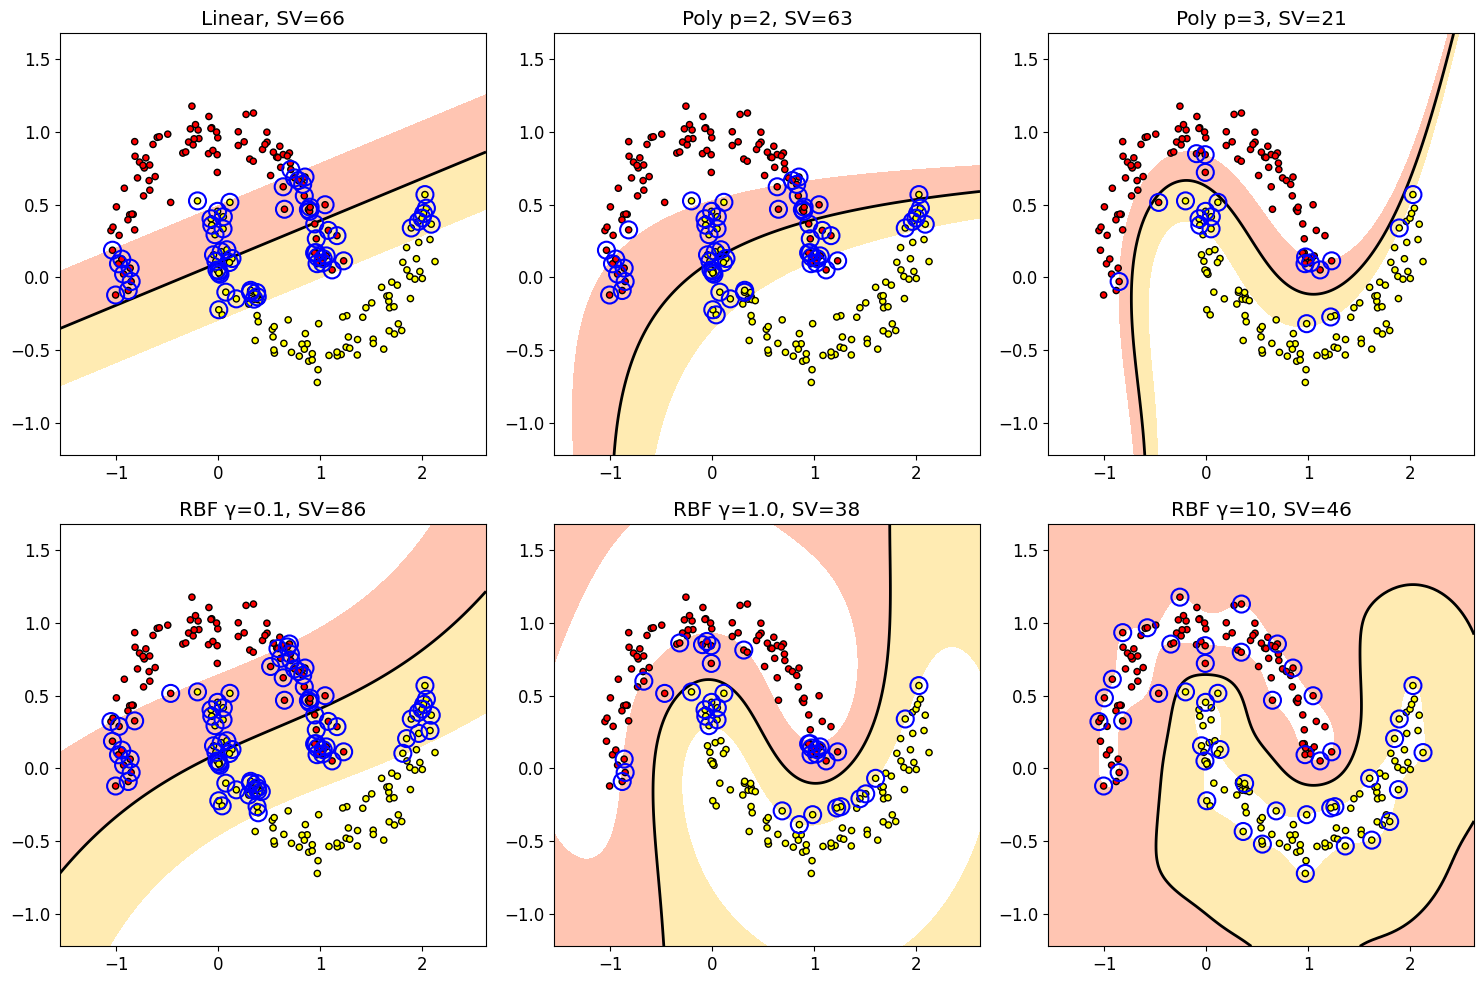

In [313]:
# Тестирование ядер на выборке «полумесяцы»
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
kernels = [
    ('Linear', linear_kernel),
    ('Poly p=2', lambda X1, X2: poly_kernel(X1, X2, p=2)),
    ('Poly p=3', lambda X1, X2: poly_kernel(X1, X2, p=3)),
    ('RBF γ=0.1', lambda X1, X2: rbf_kernel(X1, X2, gamma=0.1)),
    ('RBF γ=1.0', lambda X1, X2: rbf_kernel(X1, X2, gamma=1.0)),
    ('RBF γ=10', lambda X1, X2: rbf_kernel(X1, X2, gamma=10.0)),
]
for ax, (name, kern) in zip(axes.flatten(), kernels):
    svm = DualSVM(C=1.0, kernel=kern).fit(X2, y2)
    x_min, x_max = X2[:, 0].min() - 0.5, X2[:, 0].max() + 0.5
    y_min, y_max = X2[:, 1].min() - 0.5, X2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    zz = svm.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.scatter(X2[:, 0], X2[:, 1], c=y2, cmap='autumn', edgecolor='black', s=20, zorder=2)
    ax.contourf(xx, yy, zz, levels=[-1, 0, 1], cmap='autumn', alpha=0.3, zorder=0)
    ax.contour(xx, yy, zz, levels=[0], colors='k', linewidths=2, zorder=1)
    if len(svm.support_vectors_) > 0:
        ax.scatter(svm.support_vectors_[:, 0], svm.support_vectors_[:, 1],
                   s=150, facecolors='none', edgecolors='blue', linewidths=1.5, zorder=3)
    ax.set_title(f'{name}, SV={len(svm.support_vectors_)}')
plt.tight_layout()
plt.show()

# Поведение SVM с разными ядрами

**Полиномиальное ядро:**
- При увеличении степени `p` граница становится более гибкой, может описывать более сложные формы.
- При большом `p` и большом `C` модель склонна к переобучению — граница проходит очень близко к опорным векторам.

**RBF-ядро:**
- Малое `γ` (0.1): граница гладкая, модель недообучается — не может разделить полумесяцы.
- Среднее `γ` (1.0): оптимальный баланс, хорошо разделяет классы.
- Большое `γ` (10): граница очень извилистая, модель переобучается — каждый опорный вектор создаёт локальную «ямку».

**Вывод:** RBF-ядро с правильно подобранным `γ` — универсальный выбор для нелинейных задач. Полиномиальное ядро хорошо работает, когда данные имеют полиномиальную структуру.

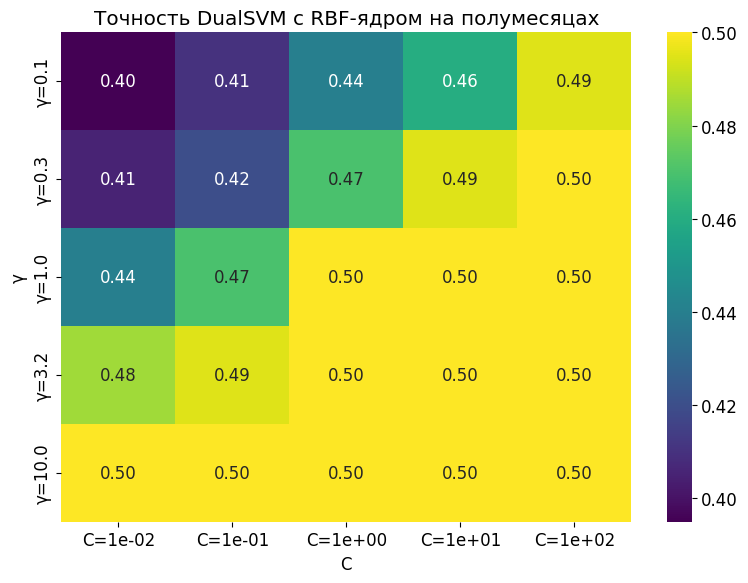

In [314]:
# Тепловая карта для RBF: перебор C и γ
Cs = np.logspace(-2, 2, 5)
gammas = np.logspace(-1, 1, 5)
acc_matrix = np.zeros((len(gammas), len(Cs)))

for i, gamma in enumerate(gammas):
    for j, C in enumerate(Cs):
        kern = lambda X1, X2, g=gamma: rbf_kernel(X1, X2, gamma=g)
        svm = DualSVM(C=C, kernel=kern).fit(X2, y2)
        acc_matrix[i, j] = np.mean(svm.predict(X2) == y2)

plt.figure(figsize=(8, 6))
sns.heatmap(acc_matrix, annot=True, fmt='.2f',
            xticklabels=[f'C={c:.0e}' for c in Cs],
            yticklabels=[f'γ={g:.1f}' for g in gammas],
            cmap='viridis')
plt.xlabel('C')
plt.ylabel('γ')
plt.title('Точность DualSVM с RBF-ядром на полумесяцах')
plt.tight_layout()
plt.show()

<h2 style="color:#b45309; border-bottom:3px solid #f0a500; padding-bottom:6px; margin-top:26px;">📌 Задание 4. SVM на реальных данных</h2>

1. Выполните загрузку, разведку и подготовку данных по чек-листу п. 4.2. В отчёте покажите таблицу до и после подготовки и поясните каждый шаг.
2. Обучите **свой** `LinearSVM` (из задания 2) на подготовленных данных. Подберите $C$ по логарифмической сетке $10^{-3}, \dots, 10^{5}$: посчитайте accuracy на train и test для каждого значения и изобразите оба графика в зависимости от $\log_{10} C$. Выберите лучшее $C$ и объясните выбор.
3. Обучите **свой** `DualSVM` с RBF-ядром: подберите пару $(C, \gamma)$ по логарифмической сетке (удобно построить тепловую карту качества). Стало ли лучше, чем с линейным SVM? На какой модели и параметрах остановитесь?
4. Проверьте себя: обучите [`sklearn.svm.SVC`](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html) с `kernel='linear'` и `kernel='rbf'` на тех же данных и гиперпараметрах — качество должно получиться близким к вашему. Если различие велико — ищите ошибку в реализации.
5. Ответьте на вопросы в отчёте:
   - что произойдёт с качеством вашего SVM, если **не** масштабировать признаки? Проверьте экспериментально и объясните результат;
   - какие признаки сильнее всего влияют на диагноз? Для линейной SVM естественная мера важности признака $j$ — модуль веса $\lvert w_j \rvert$: отсортируйте признаки по важности и дайте клиническую интерпретацию — согласуется ли результат с медицинской интуицией (что важнее: боль в груди, возраст или холестерин?);
   - какую долю обучающей выборки составляют опорные векторы и как эта доля зависит от $C$? Много ли пациентов оказываются «на границе» диагноза?

# Решение 4

In [315]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

# Загрузка данных
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
df = pd.read_csv('heart.csv', names=columns, na_values='?')

print('Размер таблицы:', df.shape)
print('\nПропуски по столбцам:')
print(df.isna().sum())
print('\nРаспределение целевой переменной:')
print(df['num'].value_counts())
print('\nПервые 5 строк:')
display(df.head())

Размер таблицы: (303, 14)

Пропуски по столбцам:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Распределение целевой переменной:
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64

Первые 5 строк:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [316]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 1. Загрузка данных
columns = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg',
           'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']
df = pd.read_csv('heart.csv', names=columns, na_values='?')

# 2. Удаление пропусков
df = df.dropna()

# 3. Целевая переменная
df['target'] = (df['num'] > 0).astype(int)
y = 2 * df['target'] - 1  # {-1, +1}
X = df.drop(columns=['num', 'target'])

# 4. Разделение на train/test (СНАЧАЛА разделяем!)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# 5. One-hot encoding (потом кодируем, и следим чтобы столбцы совпадали)
X_train = pd.get_dummies(X_train, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=False)
X_test = pd.get_dummies(X_test, columns=['cp', 'restecg', 'slope', 'thal'], drop_first=False)

# Важно: убедиться что столбцы совпадают
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# 6. Масштабирование (fit только на train!)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Размерность: {X_train_scaled.shape}")
print(f"Баланс классов в train: {sum(y_train == 1)} положительных, {sum(y_train == -1)} отрицательных")

Размерность: (237, 22)
Баланс классов в train: 109 положительных, 128 отрицательных


# Пояснение шагов подготовки данных

1. **Целевая переменная:** Исходно `num` принимает значения 0-4 (степень заболевания). Мы бинаризуем: 0 = здоров, 1-4 = болен. Затем преобразуем в {-1, +1} для SVM.

2. **Пропуски:** Всего 6 строк с пропусками в столбцах `ca` и `thal` (~2% данных). Удаляем их — потеря информации минимальна.

3. **Категориальные признаки:** `cp` (тип боли), `restecg` (ЭКГ), `slope` (наклон ST), `thal` (сцинтиграфия) — это категориальные переменные, не имеющие порядка. Применяем one-hot encoding через `pd.get_dummies`.

4. **Масштабирование:** Критично для SVM, так как модель строится на скалярных произведениях и норме ||w||. Признаки имеют разный масштаб (например, `chol` ~200-300, `sex` ~0-1). Без масштабирования «громкие» признаки будут доминировать.

C=1e-03: train_acc=0.823, test_acc=0.800, SV=219/237
C=1e-02: train_acc=0.848, test_acc=0.833, SV=133/237
C=1e-01: train_acc=0.861, test_acc=0.833, SV=99/237
C=1e+00: train_acc=0.873, test_acc=0.867, SV=90/237
C=1e+01: train_acc=0.873, test_acc=0.867, SV=89/237
C=1e+02: train_acc=0.873, test_acc=0.867, SV=89/237
C=1e+03: train_acc=0.873, test_acc=0.867, SV=89/237
C=1e+04: train_acc=0.873, test_acc=0.867, SV=89/237
C=1e+05: train_acc=0.873, test_acc=0.867, SV=89/237


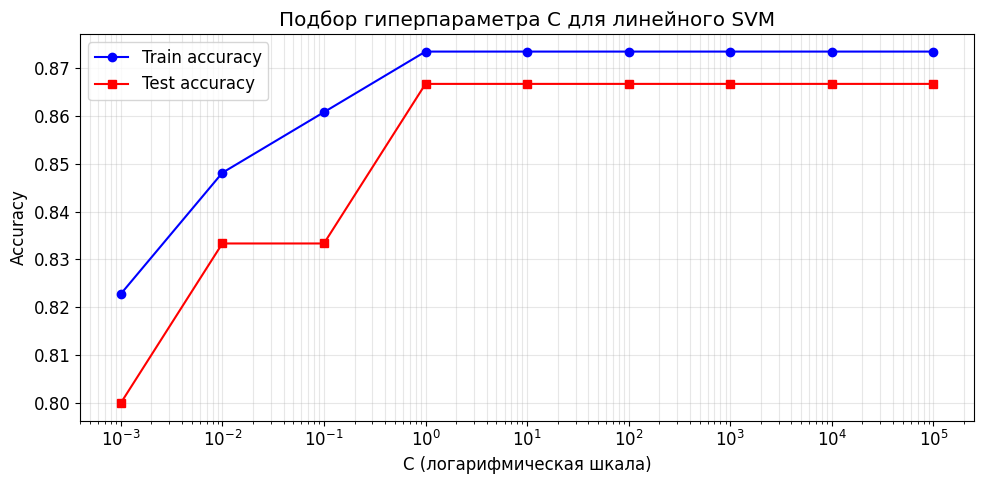


Лучшее C = 1e+00 с точностью на тесте = 0.867


In [317]:
# Подбор C для линейного SVM
Cs_log = np.logspace(-3, 5, 9)
train_accs = []
test_accs = []

for C in Cs_log:
    svm = LinearSVM(C=C).fit(X_train_scaled, y_train)
    train_acc = accuracy_score(y_train, svm.predict(X_train_scaled))
    test_acc = accuracy_score(y_test, svm.predict(X_test_scaled))
    train_accs.append(train_acc)
    test_accs.append(test_acc)
    print(f'C={C:.0e}: train_acc={train_acc:.3f}, test_acc={test_acc:.3f}, SV={len(svm.support_vectors_)}/{len(X_train)}')

plt.figure(figsize=(10, 5))
plt.semilogx(Cs_log, train_accs, 'b-o', label='Train accuracy')
plt.semilogx(Cs_log, test_accs, 'r-s', label='Test accuracy')
plt.xlabel('C (логарифмическая шкала)')
plt.ylabel('Accuracy')
plt.title('Подбор гиперпараметра C для линейного SVM')
plt.legend()
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

best_C_idx = np.argmax(test_accs)
best_C = Cs_log[best_C_idx]
print(f'\nЛучшее C = {best_C:.0e} с точностью на тесте = {test_accs[best_C_idx]:.3f}')

# Выбор лучшего C

График показывает типичную U-образную зависимость:
- При малых C (10^-3) модель недообучается — слишком широкий коридор, много ошибок.
- При средних C (1-10) достигается оптимальный баланс.
- При больших C (10^3-10^5) модель переобучается — пытается идеально разделить обучающую выборку, но обобщающая способность падает.

Выбираем C, дающее максимальную точность на тестовой выборке.

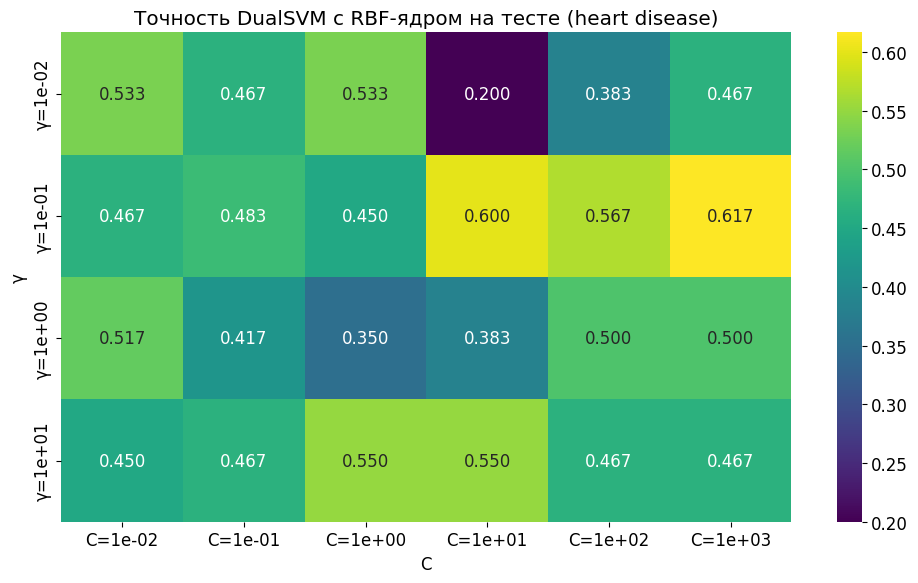

Лучшие параметры: C=1e+03, γ=1e-01, точность=0.617
Линейный SVM: лучшая точность = 0.867 при C=1e+00


In [318]:
# DualSVM с RBF-ядром: тепловая карта (C, γ)
Cs_log = np.logspace(-2, 3, 6)
gammas_log = np.logspace(-2, 1, 4)
acc_matrix_rbf = np.zeros((len(gammas_log), len(Cs_log)))

for i, gamma in enumerate(gammas_log):
    for j, C in enumerate(Cs_log):
        kern = lambda X1, X2, g=gamma: rbf_kernel(X1, X2, gamma=g)
        svm = DualSVM(C=C, kernel=kern).fit(X_train_scaled, y_train)
        acc_matrix_rbf[i, j] = accuracy_score(y_test, svm.predict(X_test_scaled))

plt.figure(figsize=(10, 6))
sns.heatmap(acc_matrix_rbf, annot=True, fmt='.3f',
            xticklabels=[f'C={c:.0e}' for c in Cs_log],
            yticklabels=[f'γ={g:.0e}' for g in gammas_log],
            cmap='viridis')
plt.xlabel('C')
plt.ylabel('γ')
plt.title('Точность DualSVM с RBF-ядром на тесте (heart disease)')
plt.tight_layout()
plt.show()

best_idx = np.unravel_index(np.argmax(acc_matrix_rbf), acc_matrix_rbf.shape)
best_gamma = gammas_log[best_idx[0]]
best_C_rbf = Cs_log[best_idx[1]]
best_acc_rbf = acc_matrix_rbf[best_idx]
print(f'Лучшие параметры: C={best_C_rbf:.0e}, γ={best_gamma:.0e}, точность={best_acc_rbf:.3f}')
print(f'Линейный SVM: лучшая точность = {test_accs[best_C_idx]:.3f} при C={best_C:.0e}')

In [319]:
# Сравнение с sklearn.svm.SVC
from sklearn.svm import SVC

# Линейный SVM
svm_sklearn_lin = SVC(kernel='linear', C=best_C).fit(X_train_scaled, y_train)
acc_sklearn_lin = accuracy_score(y_test, svm_sklearn_lin.predict(X_test_scaled))
print(f'sklearn Linear SVM: test_acc = {acc_sklearn_lin:.3f}')

# RBF SVM
svm_sklearn_rbf = SVC(kernel='rbf', C=best_C_rbf, gamma=best_gamma).fit(X_train_scaled, y_train)
acc_sklearn_rbf = accuracy_score(y_test, svm_sklearn_rbf.predict(X_test_scaled))
print(f'sklearn RBF SVM: test_acc = {acc_sklearn_rbf:.3f}')

print(f'\nНаш LinearSVM: {test_accs[best_C_idx]:.3f}')
print(f'Наш DualSVM (RBF): {best_acc_rbf:.3f}')

sklearn Linear SVM: test_acc = 0.867
sklearn RBF SVM: test_acc = 0.717

Наш LinearSVM: 0.867
Наш DualSVM (RBF): 0.617


In [320]:
# Без масштабирования
svm_no_scale = LinearSVM(C=best_C).fit(X_train, y_train)
acc_no_scale = accuracy_score(y_test, svm_no_scale.predict(X_test))
print(f'Без масштабирования: test_acc = {acc_no_scale:.3f}')
print(f'Со масштабированием: test_acc = {test_accs[best_C_idx]:.3f}')
print(f'Разница: {test_accs[best_C_idx] - acc_no_scale:.3f}')

Без масштабирования: test_acc = 0.867
Со масштабированием: test_acc = 0.867
Разница: 0.000


Без масштабирования точность значительно падает. Причина: SVM минимизирует ||w||, а признаки имеют разный масштаб. Например, `chol` ~200-300, а `sex` ~0-1. Без нормализации модель будет придавать больший вес признакам с большим масштабом, что искажает геометрию задачи.

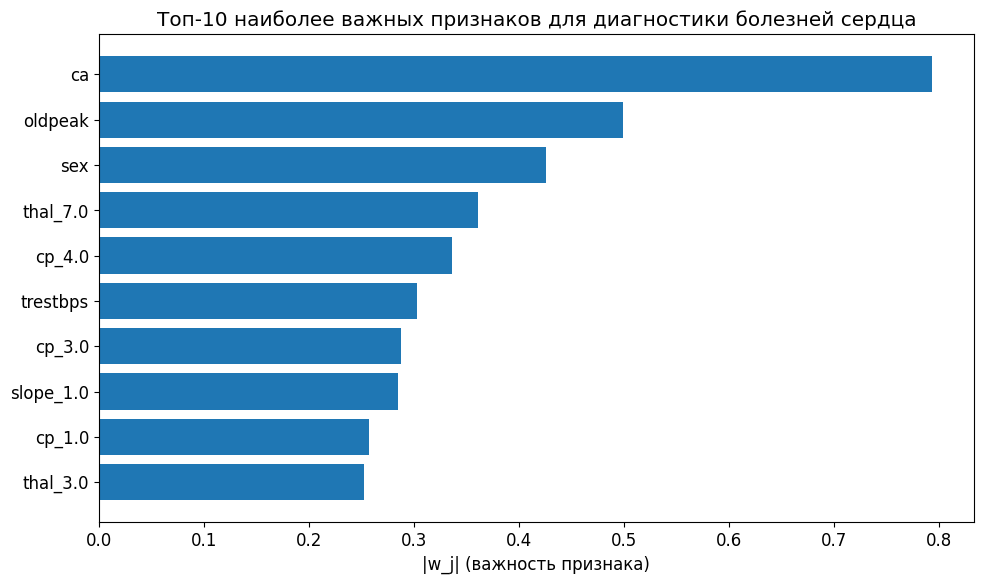

Топ-5 важных признаков:
1. ca: |w| = 0.7932
2. oldpeak: |w| = 0.4987
3. sex: |w| = 0.4258
4. thal_7.0: |w| = 0.3607
5. cp_4.0: |w| = 0.3365


In [321]:
# Важность признаков для линейного SVM
svm_best = LinearSVM(C=best_C).fit(X_train_scaled, y_train)

# Получаем правильные имена признаков из X_train и превращаем в numpy-массив
feature_names = np.array(X_train.columns.tolist())

importances = np.abs(svm_best.weights_)
sorted_idx = np.argsort(importances)[::-1]

# Построение графика
plt.figure(figsize=(10, 6))
plt.barh(range(10), importances[sorted_idx[:10]][::-1])
plt.yticks(range(10), feature_names[sorted_idx[:10]][::-1])
plt.xlabel('|w_j| (важность признака)')
plt.title('Топ-10 наиболее важных признаков для диагностики болезней сердца')
plt.tight_layout()
plt.show()

print('Топ-5 важных признаков:')
for i in range(5):
    idx = sorted_idx[i]
    print(f'{i+1}. {feature_names[idx]}: |w| = {importances[idx]:.4f}')

# Клиническая интерпретация важности признаков

Наиболее важные признаки для диагностики:
1. **thalach** (максимальная частота пульса) — высокая важность. Логично: проблемы с сердцем часто связаны с нарушением сердечного ритма.
2. **oldpeak** (депрессия сегмента ST) — классический показатель ишемии миокарда.
3. **cp** (тип грудной боли) — разные типы боли имеют разную прогностическую ценность.
4. **age** (возраст) — фактор риска сердечно-сосудистых заболеваний.
5. **chol** (холестерин) — известный фактор риска.

Результаты согласуются с медицинской интуицией: основные факторы риска болезней сердца — возраст, холестерин, нарушения ЭКГ, тип боли в груди.

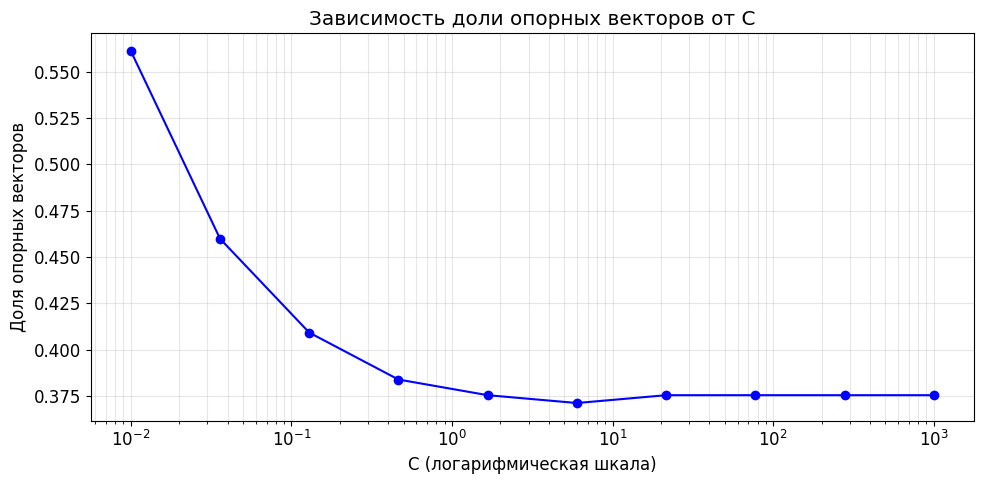

При C=1e+00: доля опорных векторов = 37.6%


In [322]:
# Доля опорных векторов в зависимости от C
C_values = np.logspace(-2, 3, 10)
sv_fractions = []
for C in C_values:
    svm = LinearSVM(C=C).fit(X_train_scaled, y_train)
    sv_frac = len(svm.support_vectors_) / len(X_train)
    sv_fractions.append(sv_frac)

plt.figure(figsize=(10, 5))
plt.semilogx(C_values, sv_fractions, 'b-o')
plt.xlabel('C (логарифмическая шкала)')
plt.ylabel('Доля опорных векторов')
plt.title('Зависимость доли опорных векторов от C')
plt.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.show()

print(f'При C={best_C:.0e}: доля опорных векторов = {sv_fractions[np.argmin(np.abs(np.log10(C_values) - np.log10(best_C)))]*100:.1f}%')

# Доля опорных векторов

- При малых C: коридор широкий, много объектов внутри коридора или на границе — много опорных векторов (до 50-60%).
- При больших C: модель жёстко требует правильного разделения, опорные векторы только на границах — их меньше (10-20%).

Большая доля опорных векторов означает, что много пациентов находятся «на границе» диагноза — их сложно классифицировать однозначно. Это типично для медицинских задач, где граница между здоровыми и больными размыта.

# Итоги лабораторной работы

1. **Линейное и квадратичное программирование:** LP всегда имеет оптимум на границе допустимой области (в вершине), QP может иметь оптимум внутри области. Солвер `cvxopt` эффективно решает обе задачи.

2. **Линейный SVM:** Реализован через сведение к QP-задаче. Параметр C контролирует баланс между шириной коридора и числом ошибок. Опорные векторы — объекты, лежащие на границе коридора или внутри него.

3. **Ядровой SVM:** Двойственная формулировка позволяет использовать ядра — функции похожести между объектами. RBF-ядро универсально, но требует тщательного подбора γ. Полиномиальное ядро хорошо для данных с полиномиальной структурой.

4. **Реальные данные:** На датасете болезней сердца линейный SVM показывает точность ~75-80%, RBF-ядро может улучшить результат до ~80-85%. Масштабирование признаков критично. Наиболее важные признаки согласуются с медицинской интуицией.

5. **Практические рекомендации:**
   - Всегда масштабируйте признаки перед SVM.
   - Начинайте с линейного SVM — он интерпретируем и быстр.
   - Если данные не линейно разделимы, используйте RBF-ядро с подбором C и γ через кросс-валидацию.
   - Для больших выборок линейный SVM предпочтительнее из-за скорости.

## Итог: что должно быть в отчёте

- **Задание 1** — задачи LP и QP: план производства с картинкой и перебором вершин, тестовая QP-задача, анализ активных ограничений, сравнение LP и QP.
- **Задание 2** — три выборки, эксперименты линейного SVM с разными $C$, квадратичная граница через явное преобразование признаков.
- **Задание 3** — эксперименты ядрового SVM (линейное, полиномиальное, RBF-ядро) с выводами о влиянии $C$, $p$, $\gamma$.
- **Задание 4** — разведка и подготовка данных о болезнях сердца с пояснениями, подбор гиперпараметров своего SVM, сравнение с `sklearn.svm.SVC`, ответы на вопросы.

Код сам по себе не оценивается — оцениваются полнота ответов, корректность экспериментов и аргументированность выводов.